# Olist P02B: Phân tích mô tả sau tiền xử lý

Dữ liệu từ P02A được lưu tại `~/Downloads/olist_preprocessed.csv`, trong thư mục Downloads.

## Nguyên tắc vận hành
- **Order item:** GMV, giá, danh mục.
- **Order:** review, ngày giao, giao trễ, thanh toán.
- **Seller:** quy mô, doanh số, chất lượng và nhãn.

Không sử dụng một view cho tất cả chỉ số vì sẽ làm lặp review và các biến chỉ có một giá trị trên mỗi đơn.


## 0. Thiết lập và nạp dữ liệu đã xử lý

Nạp thư viện, xác định thư mục dự án, tạo thư mục hình và đọc CSV `~/Downloads/olist_preprocessed.csv`.

**Đầu vào:** `olist_preprocessed.csv` trong thư mục Downloads của người dùng.

**Đầu ra:** DataFrame `df_delivered` đúng grain order item và hàm `save_fig`.

**Điểm cần kiểm tra sau khi chạy:**
- Tệp CSV phải tồn tại.
- Số dòng kỳ vọng là 110.187.
- Không chạy EDA trực tiếp trên raw data.


In [31]:
# ===== p02b — DESCRIPTIVE ANALYSIS (mục 2.3) — CHẠY ĐỘC LẬP =====

import os
from pathlib import Path
import sys
BASE = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
os.chdir(BASE)
OUT_DIR = BASE / 'preprocess_out'; FIG_DIR = BASE / 'preprocess_figs'
for _d in (OUT_DIR, FIG_DIR): _d.mkdir(exist_ok=True)
try: sys.stdout.reconfigure(encoding='utf-8')
except Exception: pass

import pandas as pd

# ---------- Nạp bảng ĐÃ tiền xử lý (đúng grain: 1 dòng = 1 order item) ----------
# ---------- Nạp CSV đã tiền xử lý từ Downloads ----------
CSV_PATH = Path.home() / 'Downloads' / 'olist_preprocessed.csv'
if not CSV_PATH.is_file():
    raise FileNotFoundError(f'Không tìm thấy CSV dữ liệu đã tiền xử lý: {CSV_PATH}')
df_delivered = pd.read_csv(CSV_PATH, parse_dates=['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
                                                   'order_delivered_customer_date', 'order_estimated_delivery_date', 'shipping_limit_date'])
print(f'Đã nạp df_delivered: {len(df_delivered):,} dòng × {df_delivered.shape[1]} cột từ {CSV_PATH}')


Đã nạp df_delivered: 110,187 dòng × 40 cột từ C:\Users\ttranhan\Downloads\olist_preprocessed.csv


## 2.3.0 Chuẩn bị 3 view đúng grain

Tách dữ liệu thành ba view để mỗi chỉ số được tính đúng độ hạt.

**Đầu vào:** `df_delivered`.

**Đầu ra:** `items_d`, `orders_d`, `seller_desc`.

**Điểm cần kiểm tra sau khi chạy:**
- `items_d`: doanh thu, danh mục, giá.
- `orders_d`: review, giao hàng, thanh toán.
- `seller_desc`: đặc trưng seller.

> **Lưu ý:** Không tính review trung bình ở grain order item khi tạo nhãn seller; nên gộp order-seller nếu một đơn có nhiều seller.

In [33]:
#### 2.3.0 Chuẩn bị 3 view đúng grain

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid')

def save_fig(name):
    plt.tight_layout()
    output_path = FIG_DIR / f'{name}.png'
    plt.savefig(output_path, dpi=150)
    display(Image(filename=str(output_path)))
    plt.close()

# View 1 — mức ORDER ITEM: dùng cho doanh thu, category, giá
items_d = df_delivered.copy()
items_d['same_state'] = (items_d['seller_state'] == items_d['customer_state'])

# View 2 — mức ORDER: dùng cho review, thời gian giao, giao trễ, thanh toán
orders_d = df_delivered.groupby('order_id').agg(
    purchase_ts=('order_purchase_timestamp', 'first'),
    delivered_ts=('order_delivered_customer_date', 'first'),
    estimated_ts=('order_estimated_delivery_date', 'first'),
    n_items=('order_item_id', 'count'),
    n_sellers=('seller_id', 'nunique'),
    gmv=('price', 'sum'),
    freight=('freight_value', 'sum'),
    delivery_days=('delivery_days', 'first'),
    is_late=('is_late', 'first'),
    review_score=('review_score', 'first'),
    customer_state=('customer_state', 'first'),
    payment_type=('main_payment_type', 'first'),
    installments=('max_installments', 'first'),
).reset_index()
orders_d['delay_days'] = (orders_d['delivered_ts'] - orders_d['estimated_ts']).dt.days

# View 3 — mức SELLER: dùng cho phân tích seller (cùng định nghĩa với seller_profile ở mục 4.2)
seller_desc = df_delivered.groupby('seller_id').agg(
    seller_state=('seller_state', 'first'),
    n_orders=('order_id', 'nunique'),
    gmv=('price', 'sum'),
    avg_price=('price', 'mean'),
    n_categories=('product_category_name_english', 'nunique'),
    avg_review=('review_score', 'mean'),
    avg_delivery_days=('delivery_days', 'mean'),
    late_rate=('is_late', 'mean'),
)
MIN_ORDERS = 10                                              # cùng ngưỡng lọc seller như p05_mining.py / p06_classify.py
seller_active = seller_desc[seller_desc['n_orders'] >= MIN_ORDERS]
print(f"Seller tổng: {len(seller_desc)} | Seller đủ điều kiện (>={MIN_ORDERS} đơn): {len(seller_active)}")


Seller tổng: 2970 | Seller đủ điều kiện (>=10 đơn): 1237


## 2.3.1 Chỉ số tổng quan (KPI)

Tính quy mô dữ liệu, GMV, AOV, basket size, review, giao trễ, thời gian giao và tỷ lệ phí vận chuyển.

**Đầu vào:** Ba view đã tạo.

**Đầu ra:** Bảng KPI và `preprocess_out/kpi_summary.csv`.

**Điểm cần kiểm tra sau khi chạy:**
- 96.468 đơn delivered.
- GMV khoảng 13,22 triệu BRL.
- 90% đơn chỉ có một sản phẩm.

> **Lưu ý:** KPI dùng để xác nhận dữ liệu trước khi đi sâu vào từng chiều.

In [34]:
#### 2.3.1 Chỉ số tổng quan (KPI)

kpi = {
    'Số đơn hàng (delivered)': orders_d['order_id'].nunique(),
    'Số seller hoạt động': df_delivered['seller_id'].nunique(),
    'Số khách hàng (unique)': df_delivered['customer_unique_id'].nunique(),
    'Số category': df_delivered['product_category_name_english'].nunique(),
    'GMV - tổng giá trị hàng (BRL)': orders_d['gmv'].sum(),
    'Giá trị đơn trung bình - AOV (BRL)': orders_d['gmv'].mean(),
    'Số sản phẩm / đơn (trung bình)': orders_d['n_items'].mean(),
    'Tỷ lệ đơn chỉ có 1 sản phẩm': (orders_d['n_items'] == 1).mean(),
    'Điểm review trung bình': orders_d['review_score'].mean(),
    'Tỷ lệ đơn giao trễ': orders_d['is_late'].mean(),
    'Thời gian giao trung bình (ngày)': orders_d['delivery_days'].mean(),
    'Tổng phí ship / tổng giá hàng': orders_d['freight'].sum() / orders_d['gmv'].sum(),
}
print(pd.Series(kpi).round(3).to_string(float_format=lambda value: f'{value:,.3f}'))
pd.Series(kpi).round(3).rename('value').to_csv(OUT_DIR / 'kpi_summary.csv', encoding='utf-8-sig')




Số đơn hàng (delivered)                  96,468.000
Số seller hoạt động                       2,970.000
Số khách hàng (unique)                   93,348.000
Số category                                  72.000
GMV - tổng giá trị hàng (BRL)        13,219,874.040
Giá trị đơn trung bình - AOV (BRL)          137.039
Số sản phẩm / đơn (trung bình)                1.142
Tỷ lệ đơn chỉ có 1 sản phẩm                   0.900
Điểm review trung bình                        4.162
Tỷ lệ đơn giao trễ                            0.081
Thời gian giao trung bình (ngày)             12.554
Tổng phí ship / tổng giá hàng                 0.166


## 2.3.2 Phân tích theo thời gian

Phân tích số đơn và GMV theo tháng, ngày trong tuần và giờ mua hàng.

**Đầu vào:** `orders_d` và thời điểm mua hàng.

**Đầu ra:** Biểu đồ tháng và heatmap thứ–giờ.

**Điểm cần kiểm tra sau khi chạy:**
- Đỉnh 11/2017 có 7.288 đơn.
- Xem xét ảnh hưởng Black Friday và các tháng đầu/cuối bị thiếu dữ liệu.

> **Lưu ý:** Không dùng biến thời gian làm thước đo trực tiếp chất lượng seller nếu mục tiêu là phân loại hiệu suất seller.

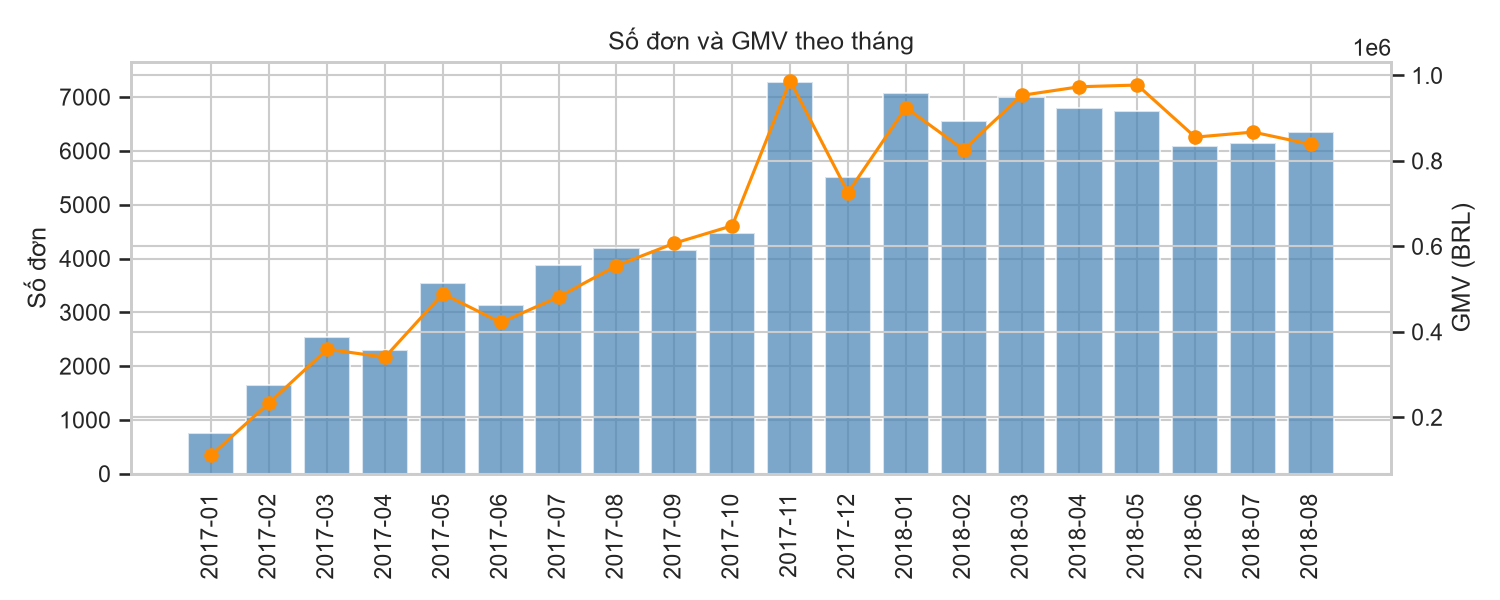

Tháng cao điểm: 2017-11 | số đơn: 7288
Tăng trưởng MoM cao nhất: 2017-02 1.203


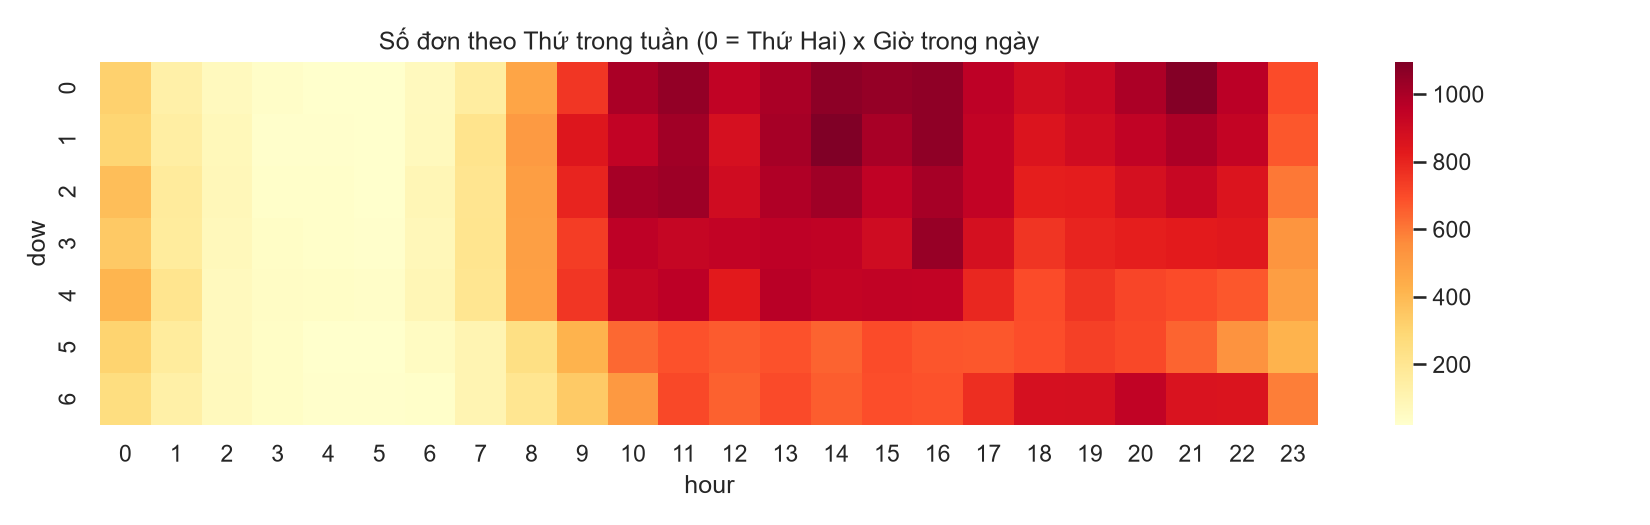

In [35]:
#### 2.3.2 Phân tích theo thời gian

monthly = (orders_d.assign(ym=orders_d['purchase_ts'].dt.to_period('M'))
           .groupby('ym').agg(n_orders=('order_id', 'nunique'), gmv=('gmv', 'sum')))
# Loại tháng đầu/cuối dataset có quá ít đơn (không đủ tháng) để không làm sai tốc độ tăng trưởng
monthly = monthly[monthly['n_orders'] >= 0.05 * monthly['n_orders'].max()]
monthly['mom_growth'] = monthly['n_orders'].pct_change()

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(monthly.index.astype(str), monthly['n_orders'], color='steelblue', alpha=0.7)
ax1.set_ylabel('Số đơn'); ax1.tick_params(axis='x', rotation=90)
ax2 = ax1.twinx()
ax2.plot(monthly.index.astype(str), monthly['gmv'], color='darkorange', marker='o')
ax2.set_ylabel('GMV (BRL)')
plt.title('Số đơn và GMV theo tháng')
save_fig('02_monthly_orders_gmv')

peak_month = monthly['n_orders'].idxmax()
print("Tháng cao điểm:", peak_month, "| số đơn:", monthly.loc[peak_month, 'n_orders'])
print("Tăng trưởng MoM cao nhất:", monthly['mom_growth'].idxmax(), round(monthly['mom_growth'].max(), 3))

# Thứ trong tuần x Giờ trong ngày
orders_d['dow'] = orders_d['purchase_ts'].dt.dayofweek      # 0 = Thứ Hai
orders_d['hour'] = orders_d['purchase_ts'].dt.hour
heat = orders_d.pivot_table(index='dow', columns='hour', values='order_id', aggfunc='count', fill_value=0)
plt.figure(figsize=(11, 3.5))
sns.heatmap(heat, cmap='YlOrRd')
plt.title('Số đơn theo Thứ trong tuần (0 = Thứ Hai) x Giờ trong ngày')
save_fig('02_dow_hour_heatmap')



## 2.3.3 Phân tích địa lý (Seller và Customer)

Mô tả phân bố seller/khách hàng theo bang và so sánh giao cùng bang với khác bang.

**Đầu vào:** `items_d`, `orders_d`.

**Đầu ra:** Biểu đồ luồng bang và bảng so sánh logistics.

**Điểm cần kiểm tra sau khi chạy:**
- SP chiếm 59,6% seller.
- Giao khác bang chậm hơn rõ rệt.

> **Lưu ý:** Địa lý có thể là biến thay thế cho hạ tầng logistics; cần thận trọng khi diễn giải công bằng.

Top 5 bang của SELLER (tỷ lệ seller):
 seller_state
SP    0.596
PR    0.113
MG    0.079
SC    0.062
RJ    0.055
Name: proportion, dtype: float64
Top 5 bang của CUSTOMER (tỷ lệ đơn):
 customer_state
SP    0.420
RJ    0.128
MG    0.118
RS    0.055
PR    0.051
Name: proportion, dtype: float64
Top-1 / Top-3 bang chiếm bao nhiêu % seller: 0.596 / 0.788
            n_items  avg_delivery_days  late_rate  avg_review  \
same_state                                                      
Khác bang     70326             15.044       0.09       4.024   
Cùng bang     39861              7.926       0.06       4.202   

            avg_freight_ratio  
same_state                     
Khác bang               0.360  
Cùng bang               0.251  


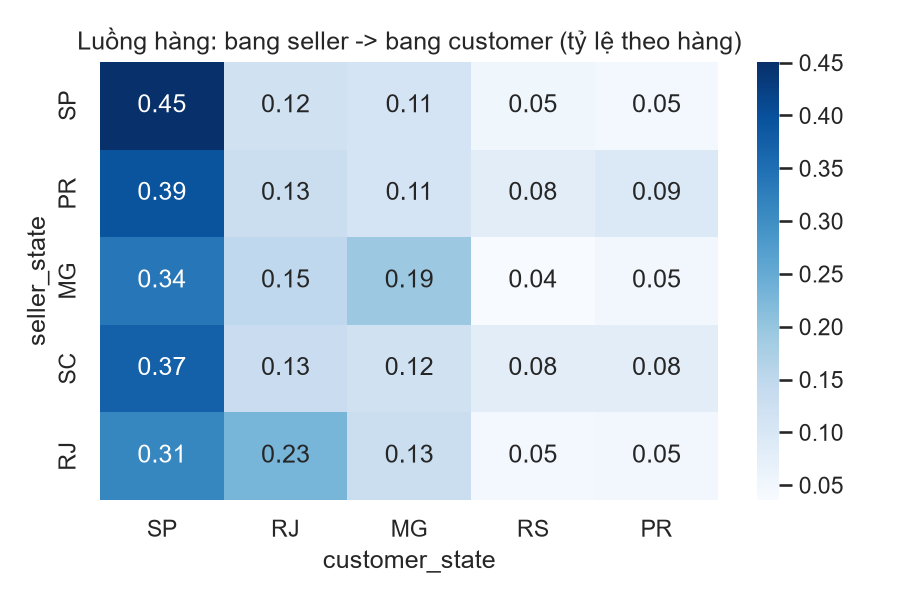

In [36]:
#### 2.3.3 Phân tích địa lý (Seller và Customer)

seller_state_share = seller_desc['seller_state'].value_counts(normalize=True)
cust_state_share = orders_d['customer_state'].value_counts(normalize=True)
print("Top 5 bang của SELLER (tỷ lệ seller):\n", seller_state_share.head(5).round(3))
print("Top 5 bang của CUSTOMER (tỷ lệ đơn):\n", cust_state_share.head(5).round(3))
print("Top-1 / Top-3 bang chiếm bao nhiêu % seller:",
      round(seller_state_share.iloc[0], 3), "/", round(seller_state_share.head(3).sum(), 3))

# Giao nội bang vs liên bang — ảnh hưởng tới logistics và trải nghiệm
geo_cmp = items_d.groupby('same_state').agg(
    n_items=('order_item_id', 'count'),
    avg_delivery_days=('delivery_days', 'mean'),
    late_rate=('is_late', 'mean'),
    avg_review=('review_score', 'mean'),
    avg_freight_ratio=('freight_value', lambda x: (x / items_d.loc[x.index, 'price']).mean()),
).rename(index={True: 'Cùng bang', False: 'Khác bang'})
print(geo_cmp.round(3))

# Ma trận luồng hàng: bang seller (hàng) -> bang customer (cột), chuẩn hoá theo hàng
top_s = seller_state_share.head(5).index
top_c = cust_state_share.head(5).index
flow = pd.crosstab(items_d['seller_state'], items_d['customer_state'], normalize='index').loc[top_s, top_c]
plt.figure(figsize=(6, 4))
sns.heatmap(flow, annot=True, fmt='.2f', cmap='Blues')
plt.title('Luồng hàng: bang seller -> bang customer (tỷ lệ theo hàng)')
save_fig('02_state_flow')


# Mức tập trung địa lý của seller so với customer; chênh lệch thời gian giao/phí ship giữa giao nội bang và liên bang -> cơ sở cho việc gắn `Region` vào `Dim_Geography` và giải thích vì sao vị trí seller ảnh hưởng đến Performance.


## 2.3.4 Phân tích Category và giá

Đánh giá mức tập trung GMV theo danh mục và phân phối giá của các danh mục lớn.

**Đầu vào:** `items_d`.

**Đầu ra:** Pareto danh mục và boxplot giá.

**Điểm cần kiểm tra sau khi chạy:**
- 18/72 danh mục tạo 80% GMV.
- Quan sát đuôi dài và ngoại lệ giá.

> **Lưu ý:** Danh mục phân tán; dùng n_categories thường gọn hơn đưa từng danh mục vào luật seller.

18/72 category tạo ra 80% GMV


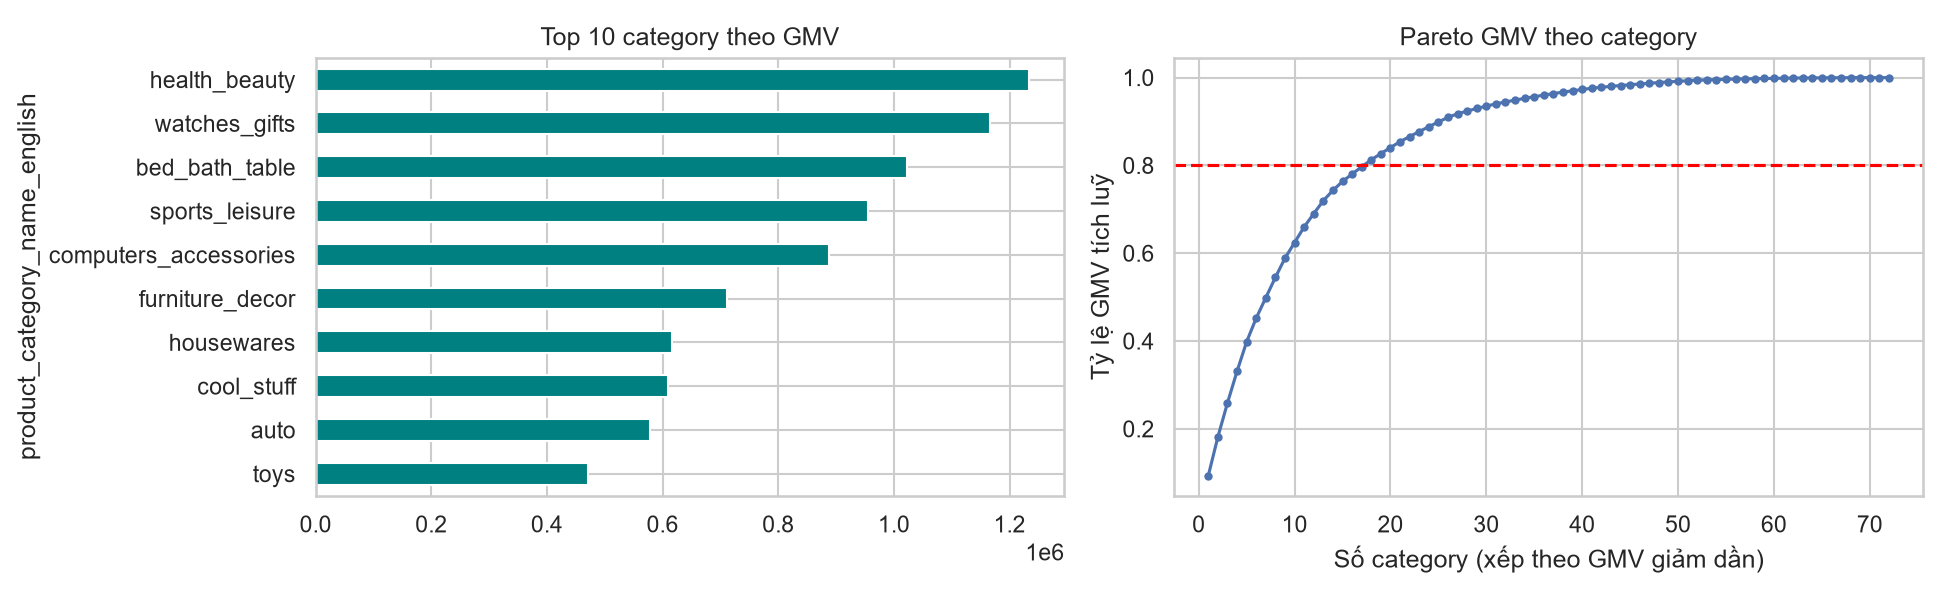

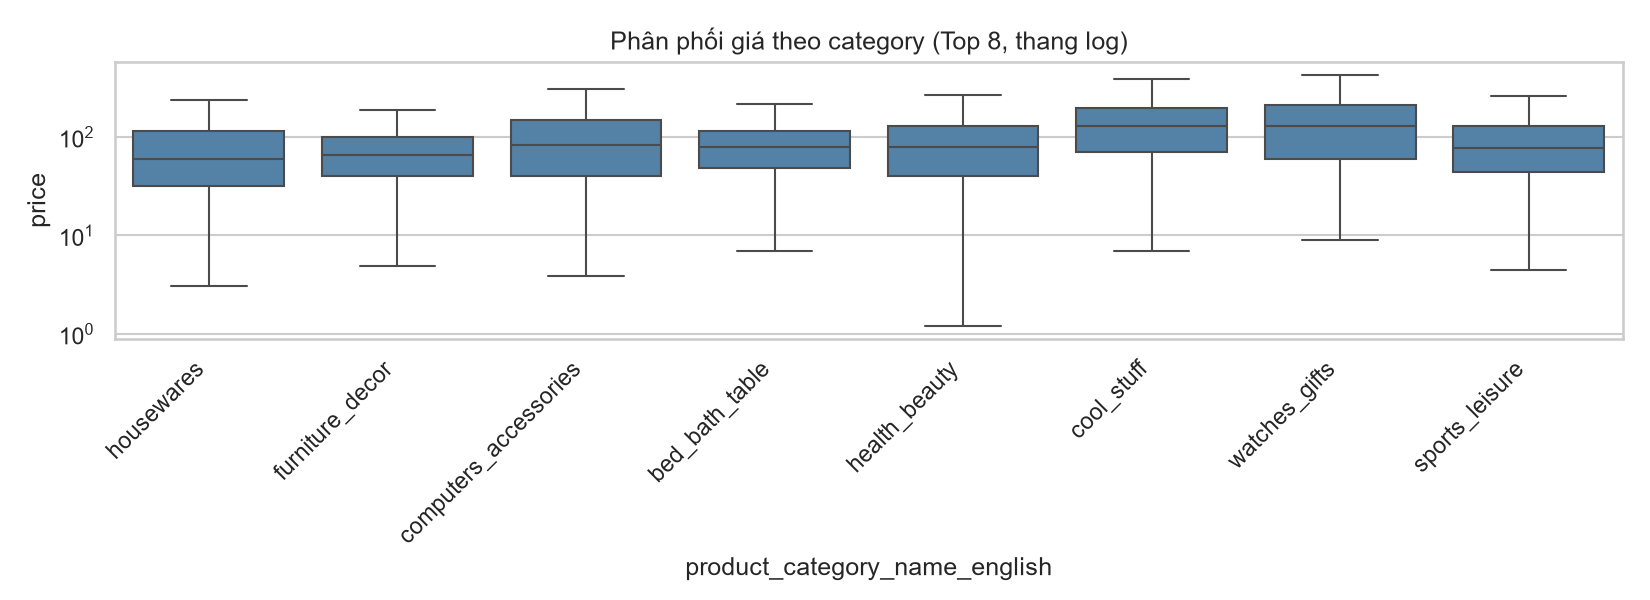

In [37]:
#### 2.3.4 Phân tích Category và giá

cat_gmv = items_d.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False)
cat_share = cat_gmv / cat_gmv.sum()
cum_share = cat_share.cumsum()
n_cat_80 = int((cum_share < 0.8).sum() + 1)
print(f"{n_cat_80}/{len(cat_gmv)} category tạo ra 80% GMV")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
cat_gmv.head(10).sort_values().plot.barh(ax=axes[0], color='teal')
axes[0].set_title('Top 10 category theo GMV')
axes[1].plot(range(1, len(cum_share) + 1), cum_share.values, marker='.')
axes[1].axhline(0.8, color='red', ls='--'); axes[1].set_xlabel('Số category (xếp theo GMV giảm dần)')
axes[1].set_ylabel('Tỷ lệ GMV tích luỹ'); axes[1].set_title('Pareto GMV theo category')
save_fig('02_category_pareto')

top8 = cat_gmv.head(8).index
plt.figure(figsize=(11, 4))
sns.boxplot(data=items_d[items_d['product_category_name_english'].isin(top8)],
            x='product_category_name_english', y='price', showfliers=False, color='steelblue')
plt.yscale('log'); plt.xticks(rotation=45, ha='right')
plt.title('Phân phối giá theo category (Top 8, thang log)')
save_fig('02_category_price_box')



## 2.3.5 Logistics và trải nghiệm khách hàng (review)

Đo mối liên hệ giữa thời gian giao, mức trễ và điểm đánh giá.

**Đầu vào:** `orders_d`.

**Đầu ra:** Biểu đồ phân phối, review theo delay bucket và kiểm định Mann–Whitney.

**Điểm cần kiểm tra sau khi chạy:**
- Đơn trễ review 2,62 so với 4,30 khi đúng hẹn.
- Kiểm tra p-value và Spearman.

> **Lưu ý:** Mối liên hệ không đồng nghĩa quan hệ nhân quả; khoảng cách và loại sản phẩm có thể gây nhiễu.

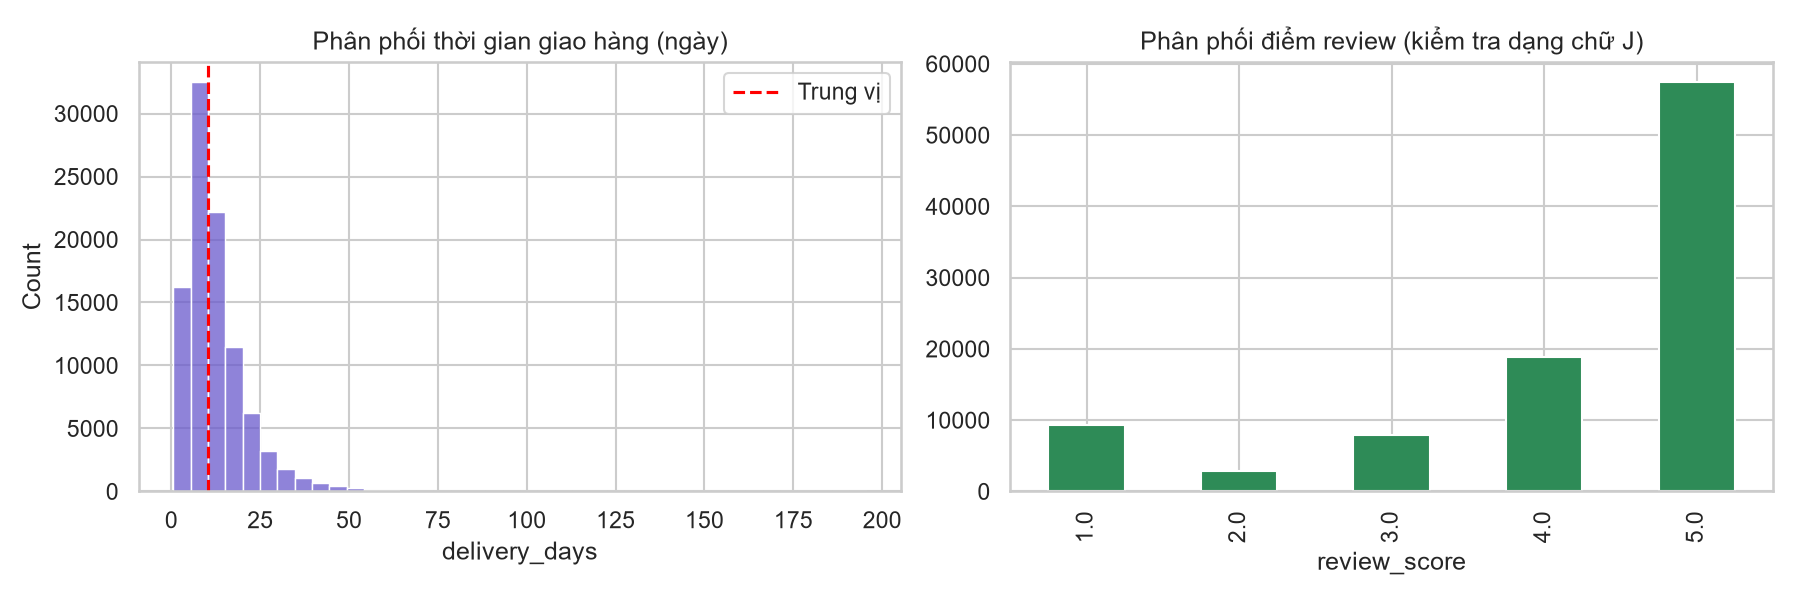

              n_orders  avg_review  pct_low_review
delay_bucket                                      
Đúng/sớm hẹn     89936       4.294           0.092
Trễ 1-3 ngày      1870       3.307           0.318
Trễ 4-7 ngày      1802       2.190           0.656
Trễ >7 ngày       2860       1.788           0.771


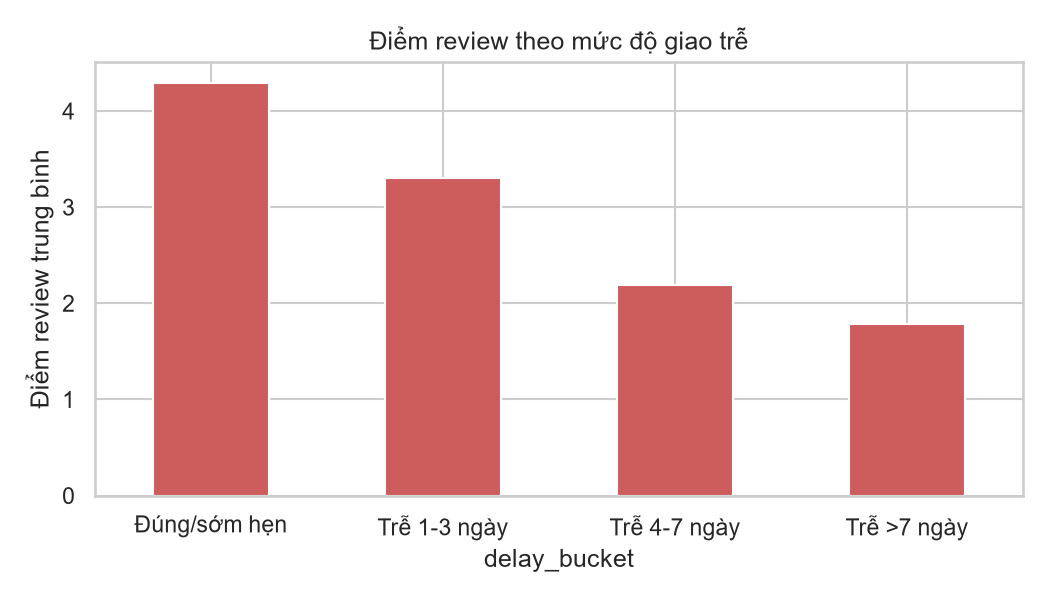

Review TB: trễ = 2.62 | đúng hẹn = 4.30 | Mann-Whitney p = 0.00e+00
Spearman(delivery_days, review_score) = -0.231 (p = 0.00e+00)


In [38]:
#### 2.3.5 Logistics và trải nghiệm khách hàng (review)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(orders_d['delivery_days'], bins=40, ax=axes[0], color='slateblue')
axes[0].axvline(orders_d['delivery_days'].median(), color='red', ls='--', label='Trung vị')
axes[0].legend(); axes[0].set_title('Phân phối thời gian giao hàng (ngày)')
orders_d['review_score'].value_counts().sort_index().plot.bar(ax=axes[1], color='seagreen')
axes[1].set_title('Phân phối điểm review (kiểm tra dạng chữ J)')
save_fig('02_delivery_review_dist')

# Mức độ trễ -> điểm review
bins_delay = [-np.inf, 0, 3, 7, np.inf]
labels_delay = ['Đúng/sớm hẹn', 'Trễ 1-3 ngày', 'Trễ 4-7 ngày', 'Trễ >7 ngày']
orders_d['delay_bucket'] = pd.cut(orders_d['delay_days'], bins=bins_delay, labels=labels_delay)
delay_tbl = orders_d.groupby('delay_bucket', observed=True).agg(
    n_orders=('order_id', 'count'),
    avg_review=('review_score', 'mean'),
    pct_low_review=('review_score', lambda s: (s <= 2).mean()),
)
print(delay_tbl.round(3))

plt.figure(figsize=(7, 4))
delay_tbl['avg_review'].plot.bar(color='indianred')
plt.ylabel('Điểm review trung bình'); plt.xticks(rotation=0)
plt.title('Điểm review theo mức độ giao trễ')
save_fig('02_review_by_delay')

# Kiểm định thống kê: review của đơn trễ có thấp hơn đơn đúng hẹn không?
late = orders_d.loc[orders_d['is_late'] == 1, 'review_score'].dropna()
ontime = orders_d.loc[orders_d['is_late'] == 0, 'review_score'].dropna()
u_stat, p_mw = stats.mannwhitneyu(late, ontime, alternative='less')
rho, p_sp = stats.spearmanr(orders_d['delivery_days'], orders_d['review_score'], nan_policy='omit')
print(f"Review TB: trễ = {late.mean():.2f} | đúng hẹn = {ontime.mean():.2f} | Mann-Whitney p = {p_mw:.2e}")
print(f"Spearman(delivery_days, review_score) = {rho:.3f} (p = {p_sp:.2e})")


# Dùng Mann-Whitney và Spearman (phi tham số) vì `review_score` là biến thứ tự, phân phối lệch hai cực — không dùng t-test. Kết quả này là **bằng chứng thống kê** cho việc dùng `late_rate` và `avg_review` làm tiêu chí nhãn Performance


## 2.3.6 Phân tích thanh toán

Mô tả tỷ trọng phương thức thanh toán và AOV theo phương thức.

**Đầu vào:** `orders_d`.

**Đầu ra:** Biểu đồ payment và bảng tỷ trọng/AOV.

**Điểm cần kiểm tra sau khi chạy:**
- Credit card chiếm khoảng 75,5%.
- So sánh AOV giữa credit card, boleto, voucher, debit card.

> **Lưu ý:** Payment có thể là tín hiệu bổ trợ, không phải yếu tố vận hành cốt lõi của seller.

Tỷ trọng phương thức thanh toán chính:
 payment_type
credit_card    0.755
boleto         0.199
voucher        0.031
debit_card     0.015
Name: proportion, dtype: float64
AOV theo phương thức:
 payment_type
boleto         121.4
credit_card    143.2
debit_card     119.7
voucher         94.8
Name: gmv, dtype: float64


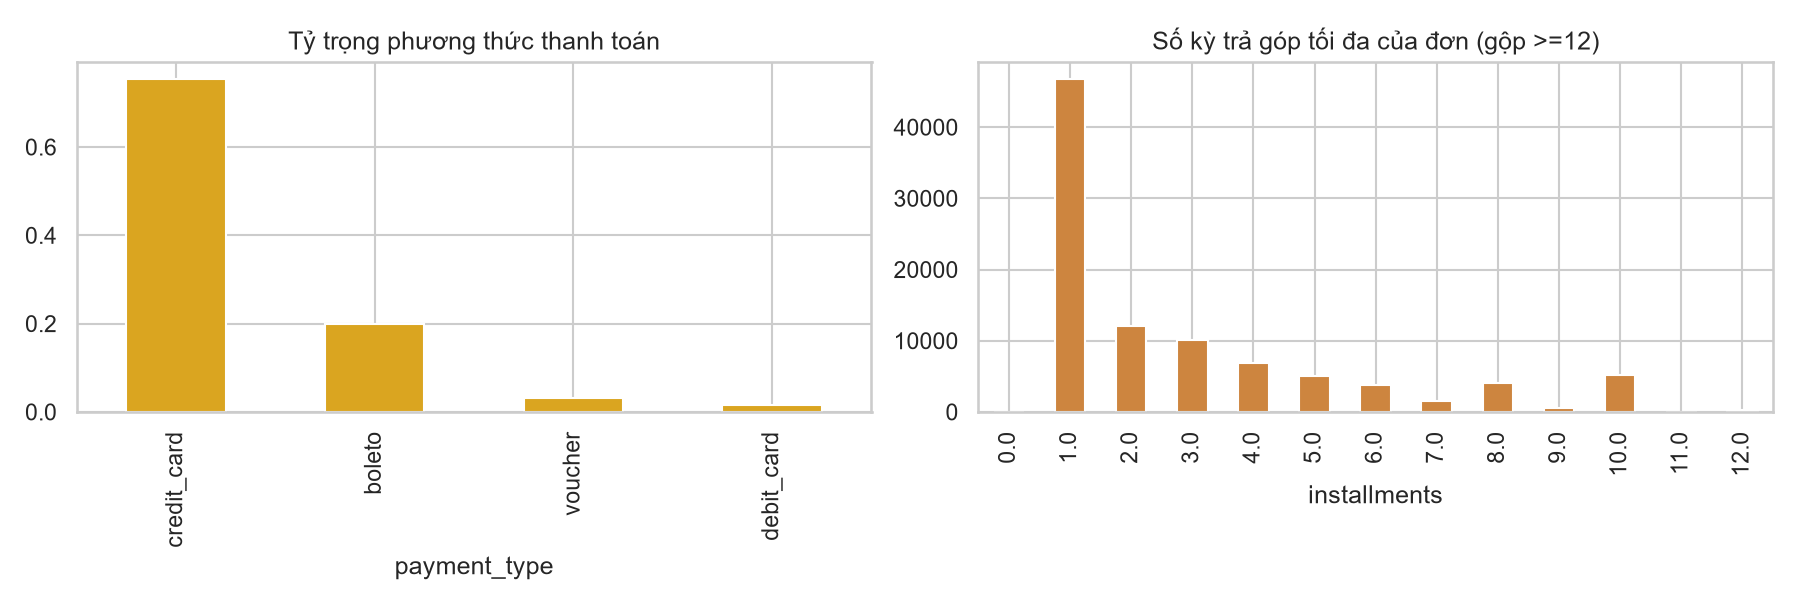

In [39]:
#### 2.3.6 Phân tích thanh toán

pay_share = orders_d['payment_type'].value_counts(normalize=True)
print("Tỷ trọng phương thức thanh toán chính:\n", pay_share.round(3))
print("AOV theo phương thức:\n", orders_d.groupby('payment_type')['gmv'].mean().round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pay_share.plot.bar(ax=axes[0], color='goldenrod'); axes[0].set_title('Tỷ trọng phương thức thanh toán')
orders_d['installments'].clip(upper=12).value_counts().sort_index().plot.bar(ax=axes[1], color='peru')
axes[1].set_title('Số kỳ trả góp tối đa của đơn (gộp >=12)')
save_fig('02_payment')


## 2.3.7 Phân tích Seller (trọng tâm của đồ án)

Đánh giá mức tập trung GMV, mối quan hệ giữa quy mô và chất lượng, tạo tập seller đủ điều kiện.

**Đầu vào:** `seller_desc`.

**Đầu ra:** Lorenz/Gini, scatter quy mô–chất lượng, bảng seller đủ điều kiện.

**Điểm cần kiểm tra sau khi chạy:**
- Gini khoảng 0,788.
- Top 10% seller chiếm 67,1% GMV.
- 1.237 seller có ít nhất 10 đơn.

> **Lưu ý:** Cần kiểm soát grain của review khi tạo nhãn Good/NeedsSupport.

       n_orders        gmv  avg_price  n_categories  avg_review  \
count   1237.00    1237.00    1237.00       1237.00     1237.00   
mean      74.25    9703.79     147.15          3.20        4.14   
std      154.11   20393.57     177.33          2.85        0.40   
min       10.00     263.13      10.16          1.00        1.93   
25%       16.00    1708.37      58.64          1.00        3.93   
50%       30.00    3908.94      98.52          2.00        4.19   
75%       69.00    9070.00     159.91          4.00        4.40   
max     1819.00  226987.93    2025.50         27.00        5.00   

       avg_delivery_days  late_rate  
count            1237.00    1237.00  
mean               12.12       0.08  
std                 3.76       0.07  
min                 4.03       0.00  
25%                 9.68       0.03  
50%                11.72       0.06  
75%                14.05       0.11  
max                37.56       0.64  
Độ lệch (skewness):
 n_orders             6.45
gmv    

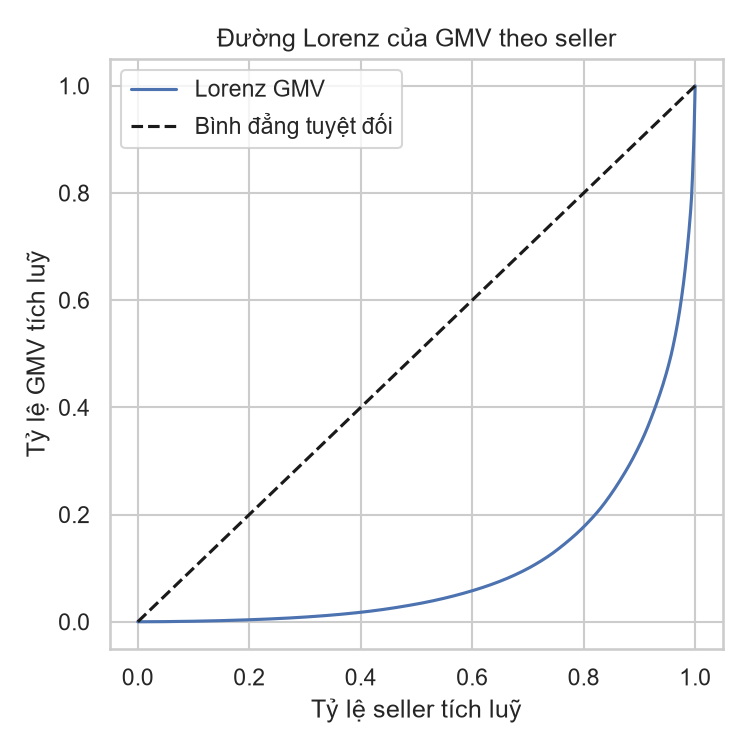

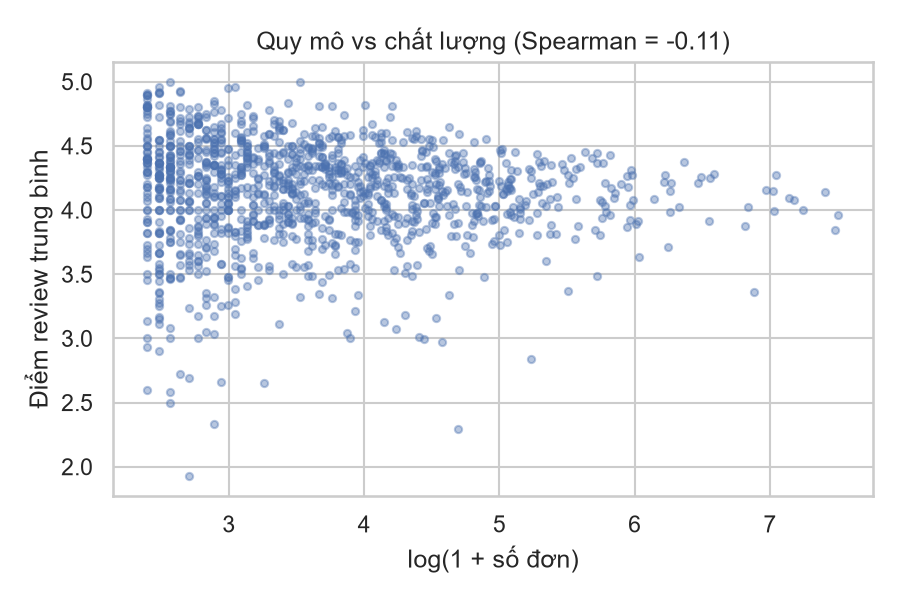

Xem trước nhãn: Good = 69.8% | NeedsSupport = 30.2%
              n_sellers  late_rate  avg_review
seller_state                                  
SC                   55      0.087       4.086
SP                  762      0.087       4.121
RJ                   69      0.075       4.132
MG                  110      0.062       4.135
RS                   41      0.056       4.206
PR                  139      0.054       4.213
DF                   16      0.053       4.259
GO                   15      0.029       4.186


In [40]:
#### 2.3.7 Phân tích Seller (trọng tâm của đồ án)

# (a) Thống kê mô tả + độ lệch (skewness) — cơ sở chọn log-transform và qcut ở mục 4.4
cols = ['n_orders', 'gmv', 'avg_price', 'n_categories', 'avg_review', 'avg_delivery_days', 'late_rate']
print(seller_active[cols].describe().round(2))
skew = seller_active[cols].skew().sort_values(ascending=False)
print("Độ lệch (skewness):\n", skew.round(2))
print("Feature lệch mạnh (|skew| > 1):", skew[skew.abs() > 1].index.tolist())

# (b) Đuôi dài và mức tập trung: Lorenz curve + Gini trên GMV
g = np.sort(seller_desc['gmv'].values)
lorenz = np.insert(np.cumsum(g) / g.sum(), 0, 0)
x = np.linspace(0, 1, len(lorenz))
trapezoid = getattr(np, 'trapezoid', None) or np.trapz   # tương thích NumPy 1.x và 2.x (np.trapz đã bị gỡ ở bản mới)
gini = 1 - 2 * trapezoid(lorenz, x)
top10_share = seller_desc['gmv'].nlargest(max(1, int(0.1 * len(seller_desc)))).sum() / seller_desc['gmv'].sum()
pct_small = (seller_desc['n_orders'] < MIN_ORDERS).mean()
print(f"Gini(GMV theo seller) = {gini:.3f} | Top 10% seller chiếm {top10_share:.1%} GMV | "
      f"{pct_small:.1%} seller có < {MIN_ORDERS} đơn (bị loại ở bước mining)")

plt.figure(figsize=(5, 5))
plt.plot(x, lorenz, label='Lorenz GMV'); plt.plot([0, 1], [0, 1], 'k--', label='Bình đẳng tuyệt đối')
plt.xlabel('Tỷ lệ seller tích luỹ'); plt.ylabel('Tỷ lệ GMV tích luỹ'); plt.legend()
plt.title('Đường Lorenz của GMV theo seller')
save_fig('02_seller_lorenz')

# (c) Quy mô có đi cùng chất lượng không?
rho_sz, p_sz = stats.spearmanr(seller_active['n_orders'], seller_active['avg_review'])
plt.figure(figsize=(6, 4))
plt.scatter(np.log1p(seller_active['n_orders']), seller_active['avg_review'], alpha=0.4, s=12)
plt.xlabel('log(1 + số đơn)'); plt.ylabel('Điểm review trung bình')
plt.title(f'Quy mô vs chất lượng (Spearman = {rho_sz:.2f})')
save_fig('02_seller_scale_vs_quality')

# (d) Xem trước nhãn Performance (cùng quy tắc p05/p06: Good nếu avg_review >= 4.0; late_rate là FEATURE, không dùng để gán nhãn) — kiểm tra mất cân bằng lớp
good_mask = (seller_active['avg_review'] >= 4.0)
pct_good = good_mask.mean()
print(f"Xem trước nhãn: Good = {pct_good:.1%} | NeedsSupport = {1 - pct_good:.1%}")

# (e) Vị trí seller và tỷ lệ giao trễ (chỉ bang có đủ seller để so sánh)
state_tbl = (seller_active.groupby('seller_state')
             .agg(n_sellers=('gmv', 'size'), late_rate=('late_rate', 'mean'), avg_review=('avg_review', 'mean'))
             .query('n_sellers >= 10').sort_values('late_rate', ascending=False))
print(state_tbl.round(3).head(10))


##**Ghi chú:**
#- **(a)** feature nào lệch mạnh → chứng minh cần `np.log1p` khi clustering (5.2.2) và cần `pd.qcut` thay vì `pd.cut` khi rời rạc hoá (4.4).
#- **(b)** Gini cao + top 10% seller chiếm tỷ trọng lớn → thị trường theo mô hình "ít seller lớn, nhiều seller nhỏ"; tỷ lệ seller < 5 đơn cho biết dữ liệu bị loại ở 4.2.
#- **(c)** nếu Spearman gần 0 → quy mô không bảo đảm chất lượng, là lý do cần phân khúc theo hiệu suất chứ không chỉ theo doanh số.
#- **(d)** tỷ lệ Good/NeedsSupport thực tế cho biết trước mức mất cân bằng lớp — liên quan trực tiếp đến hệ quả của minsup toàn cục ở 4.6 và bước chọn luật cân bằng 2 lớp ở 4.8.


## 2.3.8 Tự động sinh câu insight kèm số liệu

Tổng hợp kết quả EDA thành các câu nhận định có số liệu để đưa vào báo cáo.

**Đầu vào:** Các biến thống kê đã tính ở những cell trước.

**Đầu ra:** Danh sách insight in ra console.

**Điểm cần kiểm tra sau khi chạy:**
- Mỗi câu phải lấy trực tiếp từ dữ liệu.
- Không thay số liệu bằng giả định.

> **Lưu ý:** Nếu thay đổi bộ lọc hoặc định nghĩa grain, cần chạy lại cell để cập nhật toàn bộ câu insight.

In [41]:
#### 2.3.8 Tự động sinh câu insight kèm số liệu


insights = []

pct_single = (orders_d['n_items'] == 1).mean()
insights.append(f"[Basket thưa] {pct_single:.1%} đơn chỉ có 1 sản phẩm (trung bình {orders_d['n_items'].mean():.2f} "
                f"sản phẩm/đơn) -> mining theo order_id không khả thi, chuyển sang mức Seller.")

insights.append(f"[Thời vụ] Tháng cao điểm là {peak_month} với {int(monthly.loc[peak_month, 'n_orders'])} đơn; "
                f"tăng trưởng MoM cao nhất {monthly['mom_growth'].max():.1%} ({monthly['mom_growth'].idxmax()}).")

insights.append(f"[Địa lý] Bang đứng đầu chiếm {seller_state_share.iloc[0]:.1%} số seller "
                f"(top-3 chiếm {seller_state_share.head(3).sum():.1%}); "
                f"giao khác bang mất {geo_cmp.loc['Khác bang', 'avg_delivery_days']:.1f} ngày so với "
                f"{geo_cmp.loc['Cùng bang', 'avg_delivery_days']:.1f} ngày khi cùng bang.")

insights.append(f"[Danh mục] {n_cat_80}/{len(cat_gmv)} category tạo ra 80% GMV (Pareto).")

insights.append(f"[Logistics -> review] Đơn trễ có review TB {late.mean():.2f} so với {ontime.mean():.2f} khi đúng hẹn "
                f"(chênh {ontime.mean() - late.mean():.2f} điểm, Mann-Whitney p = {p_mw:.1e}).")

insights.append(f"[Tập trung seller] Gini GMV = {gini:.2f}; top 10% seller chiếm {top10_share:.1%} GMV; "
                f"{pct_small:.1%} seller có dưới {MIN_ORDERS} đơn.")

insights.append(f"[Quy mô vs chất lượng] Spearman(số đơn, review) = {rho_sz:.2f} -> "
                + ("quy mô gần như không đảm bảo chất lượng." if abs(rho_sz) < 0.2
                   else "có mối liên hệ giữa quy mô và chất lượng."))

insights.append(f"[Nhãn Performance] Xem trước: Good = {pct_good:.1%}, NeedsSupport = {1 - pct_good:.1%} "
                f"-> {'lớp mất cân bằng đáng kể' if min(pct_good, 1 - pct_good) < 0.3 else 'lớp tương đối cân bằng'}.")

insights.append(f"[Phân phối feature] Các feature lệch mạnh (|skew| > 1): {skew[skew.abs() > 1].index.tolist()} "
                f"-> dùng log-transform và qcut.")

for i, s_ in enumerate(insights, 1):
    print(f"Insight {i}: {s_}")
(OUT_DIR / 'insights.txt').write_text('\n'.join(f'Insight {i}: {t}' for i, t in enumerate(insights, 1)), encoding='utf-8')


Insight 1: [Basket thưa] 90.0% đơn chỉ có 1 sản phẩm (trung bình 1.14 sản phẩm/đơn) -> mining theo order_id không khả thi, chuyển sang mức Seller.
Insight 2: [Thời vụ] Tháng cao điểm là 2017-11 với 7288 đơn; tăng trưởng MoM cao nhất 120.3% (2017-02).
Insight 3: [Địa lý] Bang đứng đầu chiếm 59.6% số seller (top-3 chiếm 78.8%); giao khác bang mất 15.0 ngày so với 7.9 ngày khi cùng bang.
Insight 4: [Danh mục] 18/72 category tạo ra 80% GMV (Pareto).
Insight 5: [Logistics -> review] Đơn trễ có review TB 2.62 so với 4.30 khi đúng hẹn (chênh 1.68 điểm, Mann-Whitney p = 0.0e+00).
Insight 6: [Tập trung seller] Gini GMV = 0.79; top 10% seller chiếm 67.1% GMV; 58.4% seller có dưới 10 đơn.
Insight 7: [Quy mô vs chất lượng] Spearman(số đơn, review) = -0.11 -> quy mô gần như không đảm bảo chất lượng.
Insight 8: [Nhãn Performance] Xem trước: Good = 69.8%, NeedsSupport = 30.2% -> lớp tương đối cân bằng.
Insight 9: [Phân phối feature] Các feature lệch mạnh (|skew| > 1): ['n_orders', 'gmv', 'avg_price',

1095

## 2.3.9 Bảng "Insight -> Hệ quả cho các bước sau" (điền số liệu từ output thật)

Ghi chú cách chuyển phát hiện EDA thành quyết định cho kho dữ liệu, khai phá luật và phân lớp.

**Đầu vào:** Output toàn bộ EDA.

**Đầu ra:** Không tạo dữ liệu mới; cung cấp khung diễn giải.

**Điểm cần kiểm tra sau khi chạy:**
Đối chiếu mọi giả thuyết với output thật trước khi đưa vào bài luận.

> **Lưu ý:** Phần chú thích cuối chỉ là hướng dẫn, không phải kết quả tự động.

In [42]:
#### 2.3.9 Bảng "Insight -> Hệ quả cho các bước sau" (điền số liệu từ output thật)

#| # | Insight (điền số liệu từ 2.3.8) | Ý nghĩa nghiệp vụ | Tác động tới bước nào |
#|---|---|---|---|
#| 1 | % đơn chỉ 1 sản phẩm = [X]% | Giỏ hàng quá thưa để tìm luật mua kèm theo đơn | Mục 4.1: mining theo Seller |
#| 2 | Tháng cao điểm = [Y], MoM cao nhất = [Z]% | Có thời vụ/khuyến mãi tác động lên khối lượng đơn | Mục 3: thêm `IsHolidayPeak` vào `Dim_Date`; mục 7.3: hướng mở rộng mining theo mùa |
#| 3 | Top-3 bang chiếm [A]% seller; giao khác bang chậm hơn [B] ngày | Vị trí seller ảnh hưởng logistics | Mục 3.2: `Region` trong `Dim_Geography`; giải thích Performance |
#| 4 | [N] category tạo 80% GMV | Danh mục tập trung theo Pareto | Mục 3.4: chọn category cho truy vấn OLAP mẫu |
#| 5 | Đơn trễ thấp hơn đơn đúng hẹn [D] điểm review (p < 0.05) | Giao hàng là yếu tố chi phối trải nghiệm | Mục 4.5: dùng `late_rate` + `avg_review` làm tiêu chí nhãn |
#| 6 | Gini = [G], top 10% seller = [T]% GMV | Thị trường lệch về ít seller lớn | Mục 5.2: cân nhắc tách mega-seller khỏi clustering |
#| 7 | Spearman(số đơn, review) = [R] | Quy mô có/không đồng nghĩa chất lượng | Mục 5.2.1: lý do phân khúc theo hiệu suất |
#| 8 | Good = [P]% / NeedsSupport = [100-P]% | Nhãn mất cân bằng | Mục 4.6 và 4.8: minsup toàn cục, chọn luật cân bằng 2 lớp |
#| 9 | Feature lệch mạnh = [danh sách] | Phân phối đuôi dài | Mục 4.4 (`qcut`), mục 5.2.2 (`log1p`) |

# **Giả thuyết cần đối chiếu với output thật (không phải kết luận):**
# - Seller tập trung ở một vài bang, đặc biệt bang có nền kinh tế lớn nhất.
# - Đơn giao trễ có review thấp hơn rõ rệt đơn đúng hẹn.
# - Doanh thu tập trung vào một nhóm nhỏ seller và một nhóm nhỏ category.
# - Nếu kết quả thật đi ngược giả thuyết, **hãy trình bày đúng kết quả thật** và nêu giải thích — đó là điểm cộng về tư duy phản biện.

# **Mẫu đoạn nhận xét cho báo cáo (thay [..] bằng số liệu thật):**
# > *"Sau tiền xử lý, bộ dữ liệu gồm [N_orders] đơn đã giao của [N_sellers] seller, GMV [GMV] BRL. Phân tích mô tả cho thấy [pct_single]% đơn chỉ có một sản phẩm, xác nhận việc mining ở mức Seller. Đơn giao trễ có điểm review trung bình thấp hơn [D] điểm so với đơn đúng hẹn (Mann-Whitney, p < 0.05), vì vậy `late_rate` và `avg_review` được chọn làm tiêu chí nhãn Performance. Phân phối GMV theo seller lệch mạnh (Gini = [G]), do đó các đặc trưng quy mô được log-transform và rời rạc hoá theo tần suất bằng nhau (qcut) trước khi mining."*


## Hoàn tất EDA

Các hình được lưu trong `preprocess_figs/`. Khi viết báo cáo, ưu tiên các nhận định sau:

1. Basket quá thưa để mining theo order, vì 90% đơn chỉ có một mặt hàng.
2. Giao trễ có liên hệ rất mạnh với điểm review thấp.
3. GMV tập trung vào một nhóm seller nhỏ.
4. Quy mô seller gần như không bảo đảm chất lượng.
5. Trước khi tạo nhãn seller, cần xác nhận review được tổng hợp ở grain `order_id + seller_id`, không phải trực tiếp từ dòng order item.